In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles, make_biclusters, make_blobs
from sklearn.datasets import make_classification

In [85]:
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

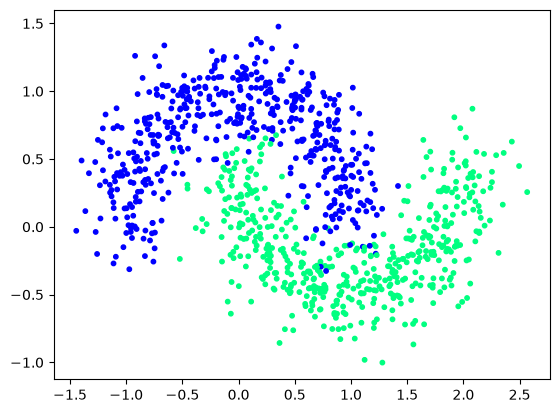

In [86]:
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=10)

In [87]:
X, y = make_circles(n_samples=1000, factor=0.5, noise=0.1, random_state=42)

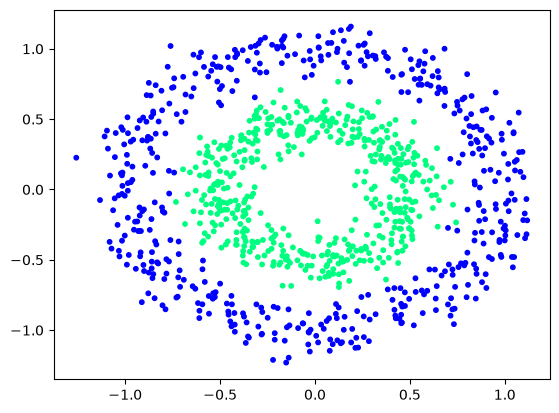

In [88]:
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=10)

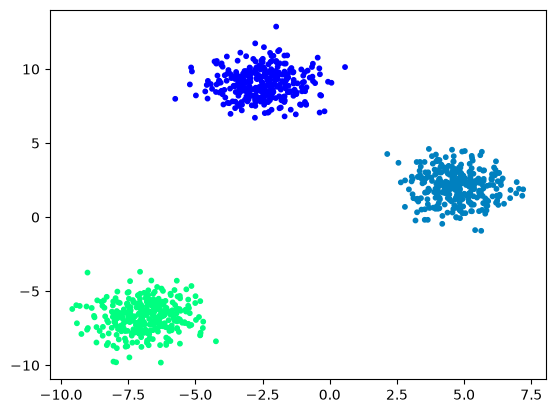

In [89]:
X, y = make_blobs(n_samples=1000, random_state=42)
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter', s=10)

In [90]:
X, y = make_classification(n_samples=1000, n_features=4, n_classes=2, random_state=42)

In [91]:
df = pd.read_csv('data/Churn_Modelling.csv')

In [92]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [93]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [94]:
df.duplicated().sum()

np.int64(0)

In [95]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [96]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [97]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [98]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [99]:
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

In [100]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [101]:
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

In [102]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [103]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['Exited'])
y = df['Exited']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [104]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [105]:
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout

In [106]:
model = Sequential([
    Input(shape=(11,)),
    Dense(10, activation='relu'),
    Dense(5, activation='relu'),
    Dense(1, activation='relu')
])


In [107]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 10)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 5)              │            55 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 181 (724.00 B)

 Trainable params: 181 (724.00 B)

 Non-trainable params: 0 (0.00 B)

In [108]:
model.compile(loss='binary_crossentropy', optimizer='Adam', metrics=["accuracy"])

In [109]:
history = model.fit(X_train_scaled, y_train, epochs=100, validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 965us/step - accuracy: 0.7520 - loss: 1.6809 - val_accuracy: 0.7538 - val_loss: 1.2331
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 475us/step - accuracy: 0.7495 - loss: 1.0155 - val_accuracy: 0.7631 - val_loss: 0.8673
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 461us/step - accuracy: 0.7588 - loss: 0.7328 - val_accuracy: 0.7681 - val_loss: 0.6217
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 457us/step - accuracy: 0.7667 - loss: 0.5910 - val_accuracy: 0.7775 - val_loss: 0.5608
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step - accuracy: 0.7752 - loss: 0.5526 - val_accuracy: 0.7875 - val_loss: 0.5204
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 481us/step - accuracy: 0.7837 - loss: 0.5237 - val_accuracy: 0.7944 - val_loss: 0.5080
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 503us/step - accuracy: 0.7892 - loss: 0.5085 - val_accuracy: 0.7962 - val_loss: 0.4995
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 522us/step - accuracy: 0.7933 - loss: 0

In [110]:
model.layers[0].get_weights()

[array([[-0.05992875,  0.09626994,  0.11150759,  0.08141985, -0.22203916,
         -0.13364725,  0.06124595, -0.05022871,  0.10850244,  0.10442585],
        [ 0.2220284 ,  0.03541404, -0.72870445,  0.39155963, -0.62170875,
          0.27955073,  0.03651449, -0.1139639 ,  0.05989793,  0.64090717],
        [-0.55384135,  0.08210109, -0.1017717 ,  0.04781253, -0.45919138,
          0.03182315, -0.34908432, -0.28444803, -0.37942964, -0.25361207],
        [-0.30110052, -0.262806  , -0.03685258, -0.06950408,  0.03179606,
          0.6563125 , -0.08119749,  0.740423  ,  0.37201297, -0.257015  ],
        [-0.28209126, -1.044332  , -0.23298556,  1.0012821 ,  0.07632246,
          0.96043247, -0.7084711 ,  0.0651048 ,  0.6088949 ,  0.27695245],
        [ 0.16902721, -0.05862596, -0.10902027,  0.14915536,  0.16857034,
         -0.19439816,  0.07336707, -0.0093072 , -0.10110801,  0.23500125],
        [ 0.03741529, -0.2894444 , -0.23604795,  0.00533789,  0.26063597,
         -0.11379499,  0.3118178

In [111]:
model.layers[1].get_weights()

[array([[ 0.32417315,  0.10837115, -0.35038266, -0.2669703 , -0.46701598],
        [ 0.5013362 ,  0.61295414, -0.68148786, -0.4291159 , -0.5409537 ],
        [-0.51606536, -0.37695506,  0.07176743, -0.24249275,  0.2706178 ],
        [-0.84684795,  0.37002546,  0.11815862, -0.43903017,  0.10386616],
        [-0.42189738,  0.20742114,  0.50587237,  0.15586118, -0.45354044],
        [-0.27185953,  0.6861477 , -0.28282776,  0.31633413, -0.02988577],
        [ 0.07956792,  0.01950122, -0.36443916, -0.7385453 ,  0.33773085],
        [ 0.5280511 ,  0.04922501,  0.0790093 ,  0.5527283 , -0.8650989 ],
        [-0.5624016 ,  0.30570075, -0.33995232,  0.1648326 , -0.2751107 ],
        [-0.29550728, -0.2564772 ,  0.29077232,  0.1563306 , -0.14321831]],
       dtype=float32),
 array([-0.05927537, -0.2398172 , -0.15462676,  0.02879994, -0.09038799],
       dtype=float32)]

In [112]:
y_pred = (model.predict(X_test_scaled) > 0.5).astype(int)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 499us/step


In [113]:
from sklearn.metrics import accuracy_score

In [114]:
print("Accuracy -> ", accuracy_score(y_test, y_pred))

Accuracy ->  0.859


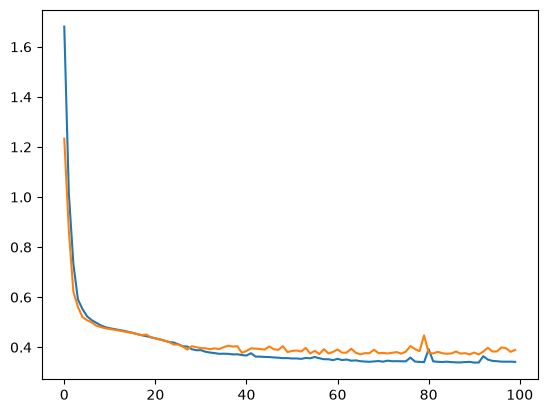

In [115]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

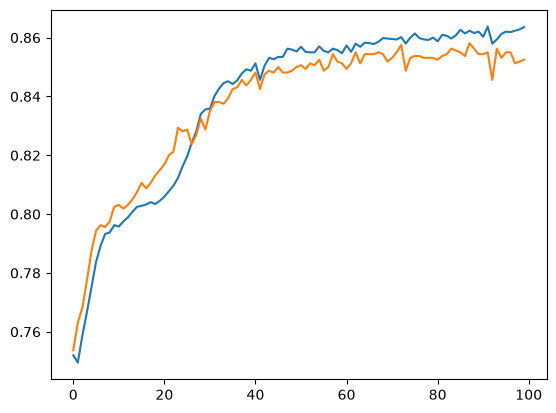

In [116]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])